# 04 余量消融与误差界收紧：本文方法 vs EKF 3σ

全文统一参数（`core.Config`）：海图配准 0.08 m（真实误差项，最坏世界里桥墙真的偏 0.08 m）、
采样保护 0.02 m（船体任一点横向速度上限 0.83 m/s × 预测步长 0.02 s）、无额外安全余量。
本 notebook 以它为基准（`base`），只改一项，看两种方法如何变化（`bridge_sim/ext.py: VARIANTS`）：

| 变体 | 改动 |
|---|---|
| `base` | 统一参数 |
| `legacy_margins` | 早期参数：采样保护 0.05 m、安全余量 0.15 m |
| `margins0` | 配准与采样保护也置 0，同时真实桥墙配准误差置 0（海图准确），A1–A2 仍成立 |
| `tight` | 本文误差盒收紧：射流梯度耦合项用北向不确定区间内的局部最大梯度；艏向项水速余量 0.20 → 0.05 m/s。仍是最坏情况界 |

两种方法在每个变体下用同样的余量；EKF 3σ 不受 `tight` 影响。

**误差界逐项分解（最坏世界、18 m 桥、断星段东向，m）**：射流幅值误差 1.56–1.77，艏向 0.22–0.25，横向速度 0.20–0.23，背景流 0.20–0.23，
梯度耦合 0.19–0.23，纵向速度 0.06–0.07；合计 2.47–2.80。真实东向误差 1.34–1.75，其中射流一项按真实北向位置积分为 1.47–1.68。
射流项本身只放大约 6%；误差盒偏松主要来自其余各项最坏值叠加（约 0.9–1.0 m），而真实世界里这些项远没到最坏或相互抵消。

In [1]:
import sys, time
from pathlib import Path
from dataclasses import replace
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from bridge_sim.ext import run_batch, pmap, gate_and_oracle, DEFAULT_SCENARIO, VARIANTS

RES = ROOT/'results'; RES.mkdir(exist_ok=True)
FIG = ROOT/'figures'; FIG.mkdir(exist_ok=True)
WORKERS = 4
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def worst_worlds8(L, variant):
    out = []
    for sj in (1, -1):
        for so in (1, -1):
            for h in (0.1, -0.1):
                out.append(replace(DEFAULT_SCENARIO, length=float(L), width=8.0, jet_amplitude_error=0.22*sj,
                                   current_north_bias=0.010*so, current_east_bias=0.011*so, tide_amplitude=0.004,
                                   gyro_bias=0.00055*so, wall_shift=-0.08*sj, initial_cross_track=0.5*so,
                                   initial_heading_error=h, variant=variant))
    return out

def cached(path, scen, methods):
    if path.exists():
        print('loading', path.name); return pd.read_csv(path)
    t0 = time.time()
    df = pd.DataFrame(run_batch(scen, methods, workers=WORKERS, progress_every=40, log_path=str(RES/'progress.log')))
    df.to_csv(path, index=False); print(f'{path.name}: {len(df)} runs in {time.time()-t0:.0f} s')
    return df

## 1. 入口认证：主实验世界，各变体最长可认证桥长

In [2]:
path = RES/'variants_gate_map.csv'
if path.exists():
    gmap = pd.read_csv(path); print('loading', path.name)
else:
    jobs = [dict(s=replace(DEFAULT_SCENARIO, length=float(L), variant=v), with_oracle=False)
            for v in VARIANTS for L in range(9, 52, 3)]
    gmap = pd.DataFrame(pmap(gate_and_oracle, jobs, workers=WORKERS))
    gmap['variant'] = [j['s'].variant for j in jobs]
    gmap.to_csv(path, index=False)
lim = pd.DataFrame({b: gmap[gmap[f'{b}_admitted'].astype(bool)].groupby('variant')['length'].max()
                    for b in ('box', 'ekf')}).rename(columns={'box': 'proposed', 'ekf': 'EKF 3σ'})
print(lim.loc[list(VARIANTS)])
gmap.pivot(index='length', columns='variant', values='box_entry_margin')[list(VARIANTS)].round(2)

loading variants_gate_map.csv
                proposed  EKF 3σ
variant                         
base                18.0    33.0
legacy_margins      18.0    33.0
margins0            21.0    36.0
tight               18.0    33.0


variant,base,legacy_margins,margins0,tight
length,,,,
9.0,1.52,1.33,1.64,1.55
12.0,1.11,0.93,1.23,1.16
15.0,0.73,0.55,0.83,0.78
18.0,0.34,0.15,0.44,0.40
21.0,-0.07,-0.25,0.03,0.01
24.0,-0.49,-0.67,-0.38,-0.39
27.0,-0.80,-0.99,-0.66,-0.67
30.0,-1.20,-1.38,-1.10,-1.08
33.0,-1.70,-1.88,-1.59,-1.55


## 2. 最坏世界闭环（声明界上 8 个世界：射流 ±0.22 × 其余误差符号 × 入口艏向 ±0.1 rad）

In [3]:
WC_L = [18, 21, 24, 30, 33, 35, 36, 37, 38]
WC_V = ['base', 'legacy_margins', 'margins0']
scen = [s for v in WC_V for L in WC_L for s in worst_worlds8(L, v)]
wc = cached(RES/'variants_worst_world.csv', scen, ('filter', 'ekf3s', 'oracle'))
assert 'error' not in wc or wc['error'].isna().all()
agg = wc.groupby(['variant', 'length']).agg(
    feasible=('oracle_feasible', 'sum'), n=('seed', 'size'),
    filter_admit=('filter_admitted', 'sum'), filter_coll=('filter_collided', 'sum'),
    filter_minclr=('filter_min_clearance', 'min'),
    ekf_admit=('ekf3s_admitted', 'sum'), ekf_coll=('ekf3s_collided', 'sum'),
    ekf_minclr=('ekf3s_min_clearance', 'min'))
agg.to_csv(RES/'variants_worst_world_summary.csv')
agg.loc[WC_V].round(3)

loading variants_worst_world.csv


feasible  n  filter_admit  filter_coll  filter_minclr  ekf_admit  ekf_coll  ekf_minclr
variant        length                                                                                        
base           18.0           8  8             8            0          1.078          8         0       0.510
               21.0           8  8             0            0            NaN          8         0       0.294
               24.0           8  8             0            0            NaN          8         0       0.041
               30.0           8  8             0            0            NaN          8         0       0.057
               33.0           8  8             0            0            NaN          8         0       0.046
               35.0           6  8             0            0            NaN          8         4      -0.002
               36.0           4  8             0            0            NaN          4         2      -0.001
               37.0           4  8             0            0            NaN          0         0         NaN
               38.0           4  8             0            0            NaN          0         0         NaN
legacy_margins 18.0           8  8             8            0          1.099          8         0       0.640
               21.0           8  8             0            0            NaN          8         0       0.408
               24.0           8  8             0            0            NaN          8         0       0.238
               30.0           8  8             0            0            NaN          8         0       0.319
               33.0           8  8             0            0            NaN          8         0       0.081
               35.0           6  8             0            0            NaN          0         0         NaN
               36.0           4  8             0            0            NaN          0         0         NaN
               37.0           4  8             0            0            NaN          0         0         NaN
               38.0           4  8             0            0            NaN          0         0         NaN
margins0       18.0           8  8             8            0          1.165          8         0       0.517
               21.0           8  8             8            0          0.992          8         0       0.351
               24.0           8  8             0            0            NaN          8         0       0.020
               30.0           8  8             0            0            NaN          8         0       0.015
               33.0           8  8             0            0            NaN          8         0       0.024
               35.0           7  8             0            0            NaN          8         0       0.003
               36.0           6  8             0            0            NaN          8         4      -0.003
               37.0           6  8             0            0            NaN          8         4      -0.002
               38.0           4  8             0            0            NaN          0         0         NaN

In [4]:
for v in WC_V:
    d = wc[wc.variant == v]
    fa, ea = d.filter_admitted.astype(bool), d.ekf3s_admitted.astype(bool)
    print(f"{v:15s} proposed: admitted {fa.sum():2d}, collided {int(d.filter_collided.sum())}, "
          f"admitted-infeasible {int((fa & ~d.oracle_feasible.astype(bool)).sum())}, max blind err/bound {d.filter_cov_ratio_E_blind.max():.2f} | "
          f"EKF 3σ: admitted {ea.sum():2d}, collided {int(d.ekf3s_collided.sum())}, "
          f"admitted-infeasible {int((ea & ~d.oracle_feasible.astype(bool)).sum())}, max blind err/3σ {d.ekf3s_cov_ratio_E_blind.max():.2f}")

base            proposed: admitted  8, collided 0, admitted-infeasible 0, max blind err/bound 0.73 | EKF 3σ: admitted 52, collided 6, admitted-infeasible 4, max blind err/3σ 1.22
legacy_margins  proposed: admitted  8, collided 0, admitted-infeasible 0, max blind err/bound 0.73 | EKF 3σ: admitted 40, collided 0, admitted-infeasible 0, max blind err/3σ 1.22
margins0        proposed: admitted 16, collided 0, admitted-infeasible 0, max blind err/bound 0.75 | EKF 3σ: admitted 64, collided 8, admitted-infeasible 5, max blind err/3σ 1.22


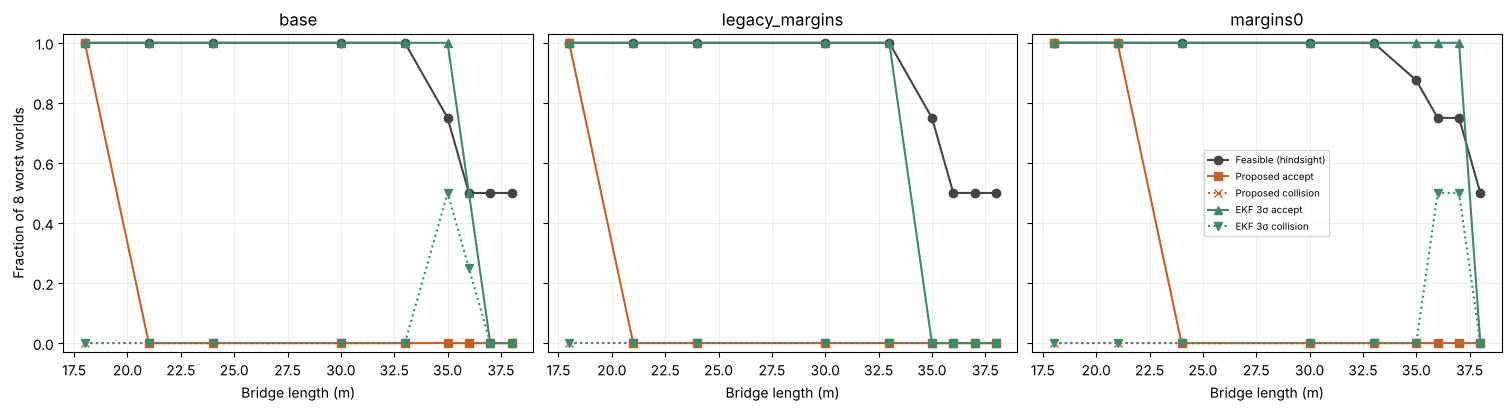

In [5]:
fig, axes = plt.subplots(1, len(WC_V), figsize=(15, 4), layout='constrained', sharey=True)
for ax, v in zip(axes, WC_V):
    a = agg.loc[v]
    ax.plot(a.index, a['feasible']/a['n'], 'o-', color='#444', label='Feasible (hindsight)')
    ax.plot(a.index, a['filter_admit']/a['n'], 's-', color='#c0612b', label='Proposed accept')
    ax.plot(a.index, a['filter_coll']/a['n'], 'x:', color='#c0612b', label='Proposed collision')
    ax.plot(a.index, a['ekf_admit']/a['n'], '^-', color='#40886c', label='EKF 3σ accept')
    ax.plot(a.index, a['ekf_coll']/a['n'], 'v:', color='#40886c', label='EKF 3σ collision')
    ax.set(title=v, xlabel='Bridge length (m)', ylim=(-.03, 1.03)); ax.grid(alpha=.2)
axes[0].set_ylabel('Fraction of 8 worst worlds'); axes[-1].legend(fontsize=7)
fig.savefig(FIG/'variants_worst_world.png', dpi=200); fig.savefig(FIG/'variants_worst_world.pdf')
plt.show()

## 结论

数字取自上面的实际运行（统一参数，横荡速度误差界 0.015 m/s）。
**统一参数（base）与早期参数（legacy_margins）对比**
- 主实验世界最长认证桥长（3 m 步长）：本文方法 18 m 对 18 m，EKF 3σ 33 m 对 33 m。18 m 的入口裕度 +0.34 m 对 +0.15 m。
- 早期参数下，EKF 3σ 在 8 个最坏世界里放行 40 次，撞墙 0；它越出 3σ 的部分被 0.15 m 安全余量和 0.05 m 采样保护吸收了。

**统一参数下的最坏世界（每个桥长 8 个世界）**
- 本文方法：放行 8 次（只有 18 m），撞墙 0，错误放行 0；断星段真实误差最多为误差界的 0.73 倍。
- EKF 3σ：放行 52 次，**撞墙 6 次**（35 m 4/8，36 m 2/4），其中 4 次是事后用任何航速都过不去的世界，即错误放行了不可通过的桥。断星段误差最多为 3σ 的 1.22 倍。
- EKF 撞墙时间隙为 −0.002 m，是擦碰；超出假设后的差别见 05。

**再去掉配准与采样保护（margins0）**：本文方法放行到 21 m（16 次），撞墙 0；EKF 3σ 放行 64 次，撞墙 8 次（36、37 m），其中 4 次放行的是不可通过的桥。

**误差界收紧（tight）几乎无效**：最长认证桥长不变（18 m），入口裕度只多 0.03–0.08 m。原因见开头的逐项分解：射流项约占误差盒的 63%，只比真实影响大约 6%；其余各项是传感器和海流误差的最坏值，在严格界的前提下压不下去。
要明显改善保守性，只能减小射流误差界本身（更好的海流图，或进桥前测射流），或在桥下获得新的位置信息。